# # 02 - Feature engineering, model training & experiment tracking
Runs the same code as `python -m heart.train`, then inspects the MLflow runs.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option("display.width", 140)

In [2]:
from heart.features import build_preprocessor, split_xy
from heart.data import load_clean
df = load_clean(); X, y = split_xy(df)
pre = build_preprocessor().fit(X)
print(pre)
print("\nEngineered feature names:", list(pre.get_feature_names_out()))

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['age', 'trestbps', 'chol', 'thalach',
                                  'oldpeak', 'ca']),
                                ('bin', SimpleImputer(strategy='most_frequent'),
                                 ['sex', 'fbs', 'exang']),
                                ('cat',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['cp', 

# ## Training and tuning
Five model families are tuned with `GridSearchCV` (5-fold stratified CV, refit on ROC-AUC) on an 80% training split; the remaining 20% is a held-out test set used only for reporting. Every grid candidate is logged to MLflow as a nested run.

In [3]:
import os; os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import warnings; warnings.filterwarnings("ignore")
from heart import train
results = train.main([])

2026/10/18 13:05:46 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


INFO logistic_regression  cv_roc_auc=0.9081 test_roc_auc=0.9221 test_acc=0.8525


2026/10/18 13:06:17 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


INFO random_forest        cv_roc_auc=0.9160 test_roc_auc=0.8929 test_acc=0.7869


2026/10/18 13:06:26 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


...

2026/10/18 13:06:36 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


INFO knn                  cv_roc_auc=0.8939 test_roc_auc=0.9048 test_acc=0.7869


Registered model 'heart-disease-classifier' already exists. Creating a new version of this model...
2026/10/18 13:06:39 WARNING mlflow.tracking._model_registry.fluent: Run with id fc709b7be4624b45932af74c69f89dcd has no artifacts at artifact path 'model', registering model based on models:/m-6621c911427949dcb3bfdc4093488d7b instead


Created version '2' of model 'heart-disease-classifier'.
INFO Champion: logistic_regression (cv_roc_auc=0.9081) -> /home/claude/heart-risk-mlops/models/model.joblib


               name  cv_roc_auc  cv_accuracy  test_roc_auc  test_accuracy  test_precision  test_recall
      random_forest      0.9160       0.8215        0.8929         0.7869          0.8261       0.6786
            svm_rbf      0.9127       0.8465        0.9113         0.8525          0.8800       0.7857
logistic_regression      0.9081       0.8504        0.9221         0.8525          0.8800       0.7857
            xgboost      0.9034       0.8134        0.8950         0.7869          0.8261       0.6786
                knn      0.8939       0.8383        0.9048         0.7869          0.8000       0.7143


In [4]:
cmp = pd.read_csv("reports/model_comparison.csv")
cols = ["name","cv_roc_auc","cv_roc_auc_std","cv_accuracy","cv_precision","cv_recall","cv_f1",
        "test_roc_auc","test_accuracy","test_precision","test_recall"]
cmp[cols].round(3)

,name,cv_roc_auc,cv_roc_auc_std,cv_accuracy,cv_precision,cv_recall,cv_f1,test_roc_auc,test_accuracy,test_precision,test_recall
0,random_forest,0.916,0.029,0.822,0.820,0.800,0.803,0.893,0.787,0.826,0.679
1,svm_rbf,0.913,0.039,0.847,0.863,0.809,0.827,0.911,0.852,0.880,0.786
2,logistic_regression,0.908,0.037,0.850,0.873,0.791,0.827,0.922,0.852,0.880,0.786
3,xgboost,0.903,0.037,0.813,0.799,0.809,0.798,0.895,0.787,0.826,0.679
4,knn,0.894,0.040,0.838,0.883,0.755,0.809,0.905,0.787,0.800,0.714


In [5]:
import json; meta = json.load(open("models/model_meta.json")); meta

{'model_name': 'logistic_regression',
 'mlflow_run_id': 'fc709b7be4624b45932af74c69f89dcd',
 'best_params': {'C': 0.1, 'l1_ratio': 0.0},
 'features': ['age',
  'trestbps',
  'chol',
  'thalach',
  'oldpeak',
  'ca',
  'sex',
  'fbs',
  'exang',
  'cp',
  'restecg',
  'slope',
  'thal'],
 'threshold': 0.5,
 'selection_rule': "1-SE rule: best=random_forest 0.9160, cutoff=0.8872, eligible=['logistic_regression', 'random_forest', 'xgboost', 'svm_rbf', 'knn']",
 'cv_roc_auc': 0.9081196581196581,
 'test_roc_auc': 0.922077922077922,
 'test_accuracy': 0.8524590163934426,
 'trained_at': '2026-10-18T13:06:39'}

# **Model selection.** Random Forest has the highest mean CV ROC-AUC, but every family lies within one standard deviation of it (fold-to-fold noise is ~0.03-0.04 AUC on 240 rows). Applying the one-standard-error rule, we pick the *simplest* model inside that band: L2-regularised Logistic Regression. It is also the best on the untouched test split, is fast, and its coefficients are directly interpretable for clinicians.

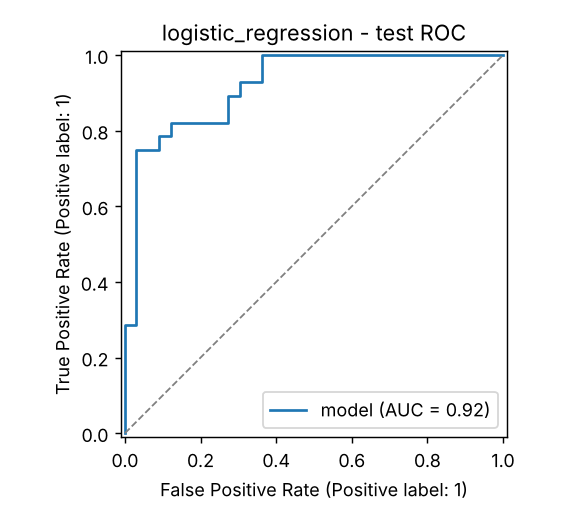

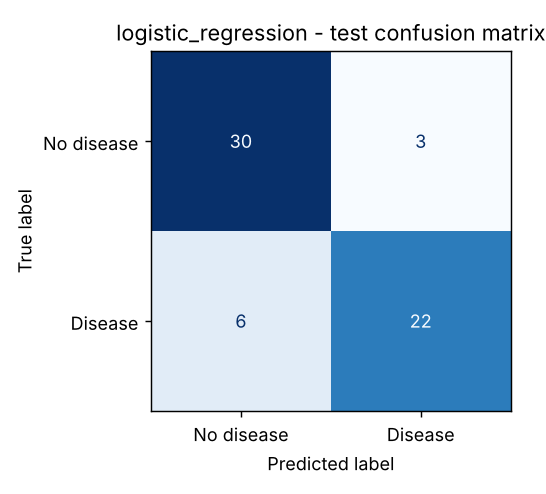

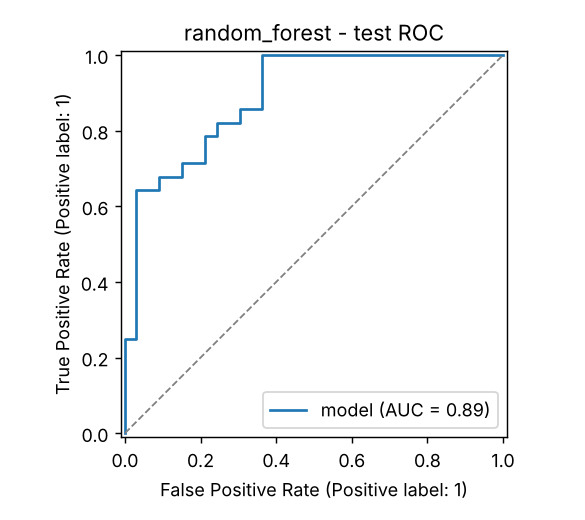

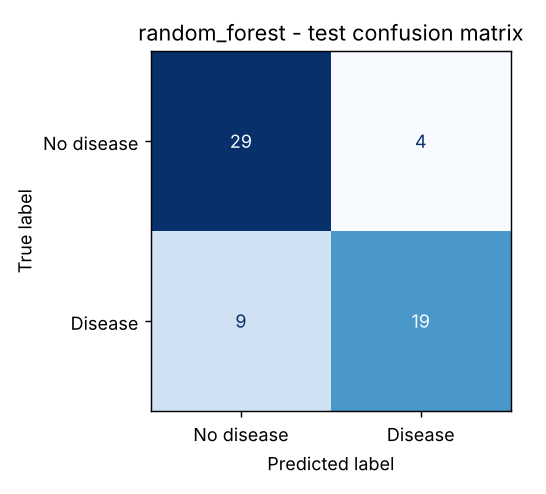

In [6]:
for name in ["logistic_regression", "random_forest"]:
    display(Image(f"reports/figures/models/{name}/roc_curve.png", width=330))
    display(Image(f"reports/figures/models/{name}/confusion_matrix.png", width=320))

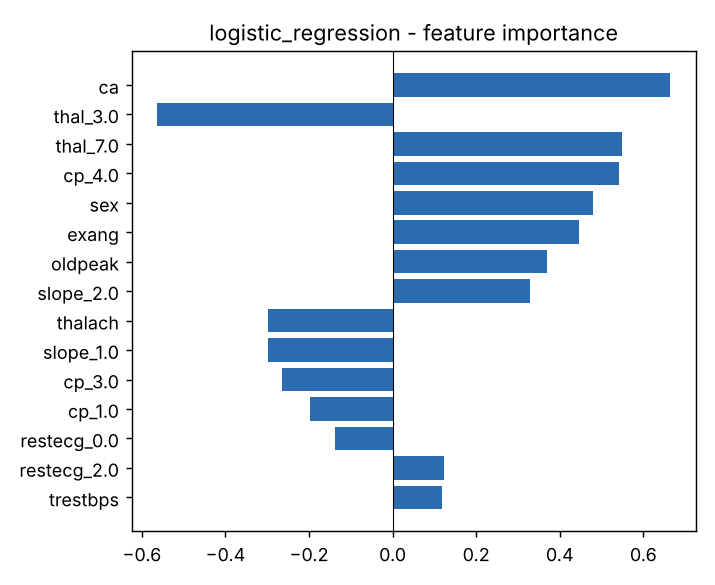

In [7]:
display(Image('reports/figures/models/logistic_regression/feature_importance.png', width=500))

# ## Querying MLflow

In [8]:
import mlflow
mlflow.set_tracking_uri("sqlite:///mlflow.db")
runs = mlflow.search_runs(experiment_names=["heart-disease-classification"])
print("total runs logged:", len(runs))
parents = runs[runs["tags.mlflow.parentRunId"].isna()]
parents[["tags.mlflow.runName","metrics.cv_roc_auc","metrics.test_roc_auc","metrics.test_accuracy"]].dropna().round(4)

total runs logged: 166


,tags.mlflow.runName,metrics.cv_roc_auc,metrics.test_roc_auc,metrics.test_accuracy
9,knn,0.8939,0.9048,0.7869
22,svm_rbf,0.9127,0.9113,0.8525
47,xgboost,0.9034,0.8950,0.7869
66,random_forest,0.9160,0.8929,0.7869
82,logistic_regression,0.9081,0.9221,0.8525
92,knn,0.8939,0.9048,0.7869
105,svm_rbf,0.9127,0.9113,0.8525
130,xgboost,0.9034,0.8950,0.7869
149,random_forest,0.9160,0.8929,0.7869
165,logistic_regression,0.9081,0.9221,0.8525


# Launch the UI with `mlflow ui --backend-store-uri sqlite:///mlflow.db` and open http://localhost:5000 to compare runs, view the logged plots and the registered model `heart-disease-classifier`.